# TED 02 — Notebook 01: Carga e inspeção da base bruta
**Projeto:** Assistente de Diagnóstico Inteligente da Inforcell · **Disciplina:** Big Data e Ciência de Dados (UNIBALSAS)
**Equipe:** Rafael R Pontara · Matheus de Brito Araujo · Pedro Junior Ubirajara · Pedro Paulo T. Araujo

Objetivo: carregar a base **Open Repair Data** (Open Repair Alliance) selecionada na TED 01, conferir sua estrutura real e levantar os problemas de qualidade **antes** de qualquer tratamento.

Versão utilizada: ORDS v0.3, exportação `202507` (dados até 31/07/2025), repositório `github.com/openrepair/data`, licença CC BY-SA 4.0.

In [1]:
import sys
sys.path.insert(0, "../../src")
import pandas as pd, numpy as np
import preparacao as prep
pd.set_option("display.max_colwidth", 80)

## 1. Estrutura geral da base completa
A TED 01 estimou ~48 mil registros e previu os campos `fault_type` e `language`. A inspeção abaixo verifica isso na versão atual.

In [2]:
arq_full = prep.RAW / prep.ARQ_AGREGADO
if arq_full.exists():
    full = prep.carregar_agregado_completo(arq_full)
    print("Base completa:", full.shape)
    print(full["product_category"].value_counts().head(10))
else:
    print("Arquivo completo (58 MB) não versionado — ver data/raw/README.md. Usando o subconjunto bruto das 4 categorias.")

Arquivo completo (58 MB) não versionado — ver data/raw/README.md. Usando o subconjunto bruto das 4 categorias.


In [3]:
bruto = prep.carregar_bruto()
print("Subconjunto bruto (Mobile, Laptop, Desktop computer, Tablet):", bruto.shape)
print("Colunas:", list(bruto.columns))
print("Campo fault_type presente?", "fault_type" in bruto.columns, "| Campo language presente?", "language" in bruto.columns)

Subconjunto bruto (Mobile, Laptop, Desktop computer, Tablet): (23612, 14)
Colunas: ['id', 'data_provider', 'country', 'partner_product_category', 'product_category', 'product_category_id', 'brand', 'year_of_manufacture', 'product_age', 'repair_status', 'repair_barrier_if_end_of_life', 'group_identifier', 'event_date', 'problem']
Campo fault_type presente? False | Campo language presente? False


In [4]:
bruto.sample(6, random_state=3).assign(problem=lambda d: d["problem"].str[:50])

,id,data_provider,country,partner_product_category,product_category,product_category_id,brand,year_of_manufacture,product_age,repair_status,repair_barrier_if_end_of_life,group_identifier,event_date,problem
6534,rcint_16899,Repair Café International,NLD,Computer equipment / phones ~ Laptop,Laptop,16,Lenovo,NaN,NaN,Fixed,NaN,Houten,2019-04-13,open office geinstalleerd en instellingen aangepas
75,anstiftung_26061,anstiftung,DEU,Computer ~ Desktopcomputer,Desktop computer,4,Sony,2009,16,Fixed,NaN,5073,2025-06-05,Fährt nicht mehr hoch. Das Betriebssystem startete
3420,rcint_115651,Repair Café International,NLD,Computer equipment / phones ~ Laptop,Laptop,16,Acer,NaN,NaN,Fixed,NaN,Waalwijk,2024-11-12,schijf kapot. gecrast. schijf vervangen door ssd.
5642,rcint_43483,Repair Café International,ESP,Computer equipment / phones ~ Tablet,Tablet,30,Apple,2019,3,End of life,NaN,Madrid Medialab Matadero,2022-09-17,"Pantalla táctil rota, aconsejamos repuestos necesa"
15056,restart_129327,The Restart Project,GBR,Laptop medium ~ Laptop,Laptop,16,Unknown,NaN,NaN,End of life,NaN,Harrow Sustain IT,2025-06-28,NaN
14229,restart_96458,The Restart Project,GBR,Laptop medium ~ Laptop,Laptop,16,Apple,2014,10,Fixed,NaN,Maidstone Repair Cafe,2024-09-07,Apple laptop over heating. Just dismantled the rea


**Achado 1 — divergência em relação à TED 01.** Na versão ORDS v0.3 a base agregada tem **305.649** registros (não ~48 mil) e **não contém** `fault_type` nem `language`. O tipo de falha só existe nas bases rotuladas das *quests* da Restart Project (MobiFix, CompCat, TabiCat), publicadas no mesmo repositório. Por isso o projeto passa a trabalhar com **duas bases complementares** (ver notebook 02).

## 2. Distribuição por categoria e tipos declarados

In [5]:
bruto["product_category"].value_counts()

product_category
Laptop              12304
Mobile               5188
Tablet               3749
Desktop computer     2371

In [6]:
# Tudo foi lido como texto de propósito: a tipagem é uma decisão da limpeza
tipos_esperados = {"event_date": "data", "year_of_manufacture": "inteiro", "product_age": "inteiro",
                   "product_category_id": "inteiro (redundante)"}
for c, t in tipos_esperados.items():
    conv = pd.to_datetime(bruto[c], errors="coerce") if t == "data" else pd.to_numeric(bruto[c], errors="coerce")
    falhas = conv.isna().sum() - bruto[c].isna().sum()
    print(f"{c:22s} -> {t:22s} | valores não conversíveis: {falhas}")

event_date             -> data                   | valores não conversíveis: 0
year_of_manufacture    -> inteiro                | valores não conversíveis: 0
product_age            -> inteiro                | valores não conversíveis: 0
product_category_id    -> inteiro (redundante)   | valores não conversíveis: 0


## 3. Dados ausentes

In [7]:
aus = (bruto.isna().mean() * 100).round(1).sort_values(ascending=False)
aus.to_frame("% ausentes")

,% ausentes
repair_barrier_if_end_of_life,95.0
product_age,69.2
year_of_manufacture,69.1
problem,24.1
id,0.0
data_provider,0.0
product_category_id,0.0
product_category,0.0
partner_product_category,0.0
country,0.0


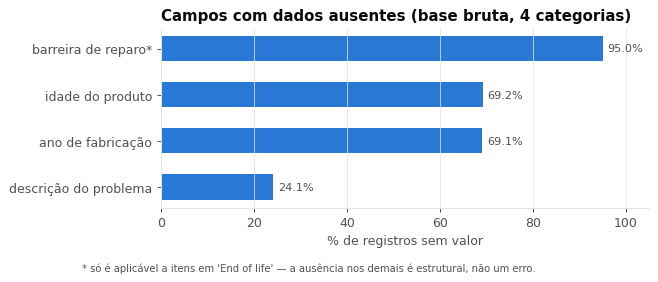

In [8]:
import graficos as g
import matplotlib.pyplot as plt
g.aplicar_estilo()
nomes = {"repair_barrier_if_end_of_life": "barreira de reparo*", "product_age": "idade do produto",
         "year_of_manufacture": "ano de fabricação", "problem": "descrição do problema"}
a = aus[aus > 0].rename(index=nomes).sort_values()
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(a.index, a.values, color=g.SERIES[0], height=0.55)
for i, v in enumerate(a.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", color=g.TXT2, fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("% de registros sem valor"); ax.grid(axis="y", visible=False)
ax.set_title("Campos com dados ausentes (base bruta, 4 categorias)")
fig.text(0, -0.16, "* só é aplicável a itens em 'End of life' — a ausência nos demais é estrutural, não um erro.", fontsize=8, color=g.TXT2)
g.salvar(fig, "fig01_ausentes")

In [9]:
# A barreira só deveria existir para 'End of life'
pd.crosstab(bruto["repair_status"], bruto["repair_barrier_if_end_of_life"].notna(), margins=True)

repair_barrier_if_end_of_life,False,True,All
repair_status,,,
End of life,2874,1173,4047
Fixed,12493,0,12493
Repairable,6205,0,6205
Unknown,867,0,867
All,22439,1173,23612


## 4. Registros duplicados

In [10]:
print("IDs duplicados:", bruto["id"].duplicated().sum())
sem_id = bruto.drop(columns=["id"])
print("Linhas idênticas em todos os campos exceto id:", sem_id.duplicated().sum())
bruto.loc[sem_id.duplicated(keep=False), "problem"].value_counts().head(10)

IDs duplicados: 0
Linhas idênticas em todos os campos exceto id: 2671


problem
NEW SSD WINDOWS 10 INSTALLED CLEANED.    186
new ssd windows 10 installed cleaned.    102
Maintainance.                             95
maintainance.                             78
SSD.                                      70
Broken screen.                            29
Cracked screen.                           24
Slow.                                     22
new ssd windows 10 instulled cleaned.     21
windows 10 installed.                     20

Os duplicados têm IDs sequenciais e textos típicos de **reparos em lote** (ex.: *"new SSD Windows 10 installed cleaned"* repetido 186 vezes em um mesmo grupo de recondicionamento). Não são erros de digitação, e sim aparelhos distintos com o mesmo serviço.

## 5. Valores inconsistentes, fora do padrão e outliers

In [11]:
ano = pd.to_numeric(bruto["year_of_manufacture"], errors="coerce")
idade = pd.to_numeric(bruto["product_age"], errors="coerce")
ano_ev = pd.to_datetime(bruto["event_date"]).dt.year
print(ano.describe().round(1))
print("Ano de fabricação posterior ao evento:", int((ano > ano_ev).sum()))
print("Ano de fabricação < 1985:", int((ano < 1985).sum()), "->", sorted(ano[ano < 1985].unique()))
print("Idade > 20 anos:", int((idade > 20).sum()))
q1, q3 = idade.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
print(f"Limite superior (IQR) da idade: {lim:.1f} anos -> {int((idade > lim).sum())} outliers estatísticos")

count    7286.0
mean     2015.3
std         5.4
min      1957.0
25%      2013.0
50%      2016.0
75%      2019.0
max      2025.0
Name: year_of_manufacture, dtype: float64
Ano de fabricação posterior ao evento: 2
Ano de fabricação < 1985: 24 -> [np.float64(1957.0), np.float64(1960.0), np.float64(1963.0), np.float64(1969.0), np.float64(1972.0), np.float64(1974.0), np.float64(1979.0), np.float64(1980.0), np.float64(1981.0), np.float64(1982.0), np.float64(1983.0), np.float64(1984.0)]
Idade > 20 anos: 113
Limite superior (IQR) da idade: 19.0 anos -> 161 outliers estatísticos


In [12]:
# Inconsistência de categorização: o que os parceiros chamam de 'Tablet'
tab = bruto[bruto["product_category"] == "Tablet"]
tab["partner_product_category"].value_counts().head(20)

partner_product_category
Tablet                                                    713
Computer equipment / phones ~ Tablet                      505
Tablet ~ Tablet                                           260
Smartphone/Tablet ~ Tablet                                221
Computer equipment / phones ~ E-reader / E-book reader    191
Tablet ~ iPad                                             172
Electrical Item ~ Tablet                                  135
Computer equipment / phones ~ iPad (tablet)               118
Computer equipment / phones ~ Navigation system            98
Tablet ~ TAblette                                          90
Handheld entertainment device ~ GSM                        78
Other ~ Weather station                                    74
Smartphone/Tablet ~ Navigationsgerät                       62
Tablet ~ Kindle                                            50
Computer equipment / phones ~ Bicycle computer             45
Tablet ~ GPS                                 

In [13]:
# Marcas: mesma marca com grafias diferentes
marca_raw = bruto["brand"].str.strip()
print("Marcas distintas (brutas):", marca_raw.nunique(), "| após lower():", marca_raw.str.lower().nunique())
ex = marca_raw[marca_raw.str.lower().isin(["apple", "appel", "iphone", "i phone", "ipad", "hp", "hewlett packard", "redmi", "unknown"])]
ex.value_counts()

Marcas distintas (brutas): 1099 | após lower(): 942


brand
Unknown            7931
Apple              2563
HP                 2032
hp                  174
appel                90
Hp                   45
apple                40
Iphone               30
iphone               27
Redmi                25
iPhone               16
iPad                 11
ipad                  9
Ipad                  7
Hewlett Packard       4
I Phone               4
Appel                 3
hewlett packard       3
IPhone                2
APPLE                 2
I phone               1
RedMi                 1

In [14]:
# Texto do problema: comprimento, placeholders e múltiplos idiomas
txt = bruto["problem"].dropna()
print(txt.str.len().describe().round(1))
print("\nExemplos aleatórios:")
for t in txt.sample(12, random_state=7): print(" -", t[:110])

count    17930.0
mean        61.7
std         83.8
min          2.0
25%         21.0
50%         39.0
75%         75.0
max       6022.0
Name: problem, dtype: float64

Exemplos aleatórios:
 - Advice given on completing repair.
 - Hoe werkt zo'n ding? uitleg gegeven.
 - Email password not known. Emails not coming down. Sorted email account for Hotmail.
 - HD fault suspected.
 - Unable to use video facility.
 - Tablette dont la fonction "appareil photo" ne fonctionne pas. Diagnostic : appareil photo introuvable.
 - Windows ne s'ouvre pas.
 - NE FONTIONNE PAS. CONTACTER SAV PAYS DE LOIRE POUR CODE RECUPERATION.
 - SSD.
 - niets. Een geheugen bijplaatsen.
 - Tablette iPad dont le mot de passe Google a été modifié.
 - installation de firefox pour remplacer microsoft edge. Défaut image. installation de firefox pour remplacer mi


In [15]:
# Atributos redundantes/irrelevantes
print("product_category_id x product_category (1:1)?",
      bruto.groupby("product_category")["product_category_id"].nunique().max() == 1)
print("group_identifier — exemplos misturando códigos e nomes:", bruto["group_identifier"].sample(6, random_state=1).tolist())
dif = (ano_ev - ano - idade).abs()
print("idade x (ano_evento - ano_fabricação): divergências > 1 ano =", int((dif > 1).sum()), "| redundância entre as duas colunas confirmada")

product_category_id x product_category (1:1)? True
group_identifier — exemplos misturando códigos e nomes: ['Oss - Megen', 'Nieuwegein', 'Repair Cafe Malmö', 'Silkeborg', 'Kolind', 'Restarters Norway']
idade x (ano_evento - ano_fabricação): divergências > 1 ano = 0 | redundância entre as duas colunas confirmada


## 6. Síntese dos problemas identificados
| # | Problema | Onde | Evidência |
|---|---|---|---|
| 1 | Estrutura diferente da prevista na TED 01 | base agregada | sem `fault_type`/`language`; 305 mil registros |
| 2 | Tipos inadequados | datas e anos como texto | necessidade de conversão explícita |
| 3 | Ausência massiva de ano/idade | `year_of_manufacture`, `product_age` | ~69% ausentes |
| 4 | Descrição ausente | `problem` | ~24% ausentes |
| 5 | Ausência estrutural | `repair_barrier` | só existe para fim de vida |
| 6 | Duplicatas (reparos em lote) | todas as colunas exceto id | ~2,7 mil linhas |
| 7 | Valores impossíveis | ano > data do evento; ano 1957 em notebook | 18 casos |
| 8 | Categorização inconsistente | Tablet inclui GPS, e-reader, estação meteorológica | ~1,1 mil registros |
| 9 | Grafias diferentes da mesma marca | `brand` | 942 valores distintos |
| 10 | Texto multilíngue e com ruído | `problem` | EN, NL, DE, FR, DA...; URLs, placeholders |
| 11 | Atributos redundantes/irrelevantes | `product_category_id`, `group_identifier`, `partner_product_category` | 1:1 ou sem uso analítico |

Os tratamentos e suas justificativas estão no **notebook 02**.